## 0. Import & nạp dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

train = pd.read_csv('../Data/train.csv')
test  = pd.read_csv('../Data/test.csv')

# Bản gốc (chưa điền) – dùng để tính mode/median, tránh rò rỉ thông tin từ test
train_raw = train.copy()
test_raw  = test.copy()

print('Train:', train.shape, '| Test:', test.shape)

Train: (1460, 81) | Test: (1459, 80)


## 1. Phân loại biến

Dựa trên mô tả dữ liệu (`data_description.txt`):

| Nhóm | Ý nghĩa | Ví dụ |
|---|---|---|
| **Số – rời rạc** | Đếm được / năm / tháng | `FullBath`, `Fireplaces`, `YearBuilt` |
| **Số – liên tục** | Diện tích, giá trị đo lường | `LotArea`, `GrLivArea`, `SalePrice` |
| **Phân loại – thứ tự** | Có thứ bậc (thang chất lượng...) | `ExterQual`, `PoolQC`, `OverallQual` |
| **Phân loại – danh nghĩa** | Không có thứ bậc | `Neighborhood`, `MSSubClass`, `CentralAir` |

`Id` là mã định danh nên tách riêng, không đưa vào mô hình.

In [2]:
ID_COL = 'Id'
TARGET = 'SalePrice'

discrete_cols = [
    'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MoSold', 'YrSold',
    'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
    'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars',
]

continuous_cols = [
    'LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
    'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
    'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch',
    '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', TARGET,
]

# Thứ tự: có thang bậc rõ ràng (OverallQual/OverallCond mã hoá bằng số 1-10 nhưng bản chất là thứ tự)
ordinal_cols = [
    'OverallQual', 'OverallCond', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
    'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'HeatingQC', 'KitchenQual',
    'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'LotShape',
    'LandSlope', 'Utilities', 'Functional', 'GarageFinish', 'PavedDrive',
]

# Danh nghĩa: tất cả cột còn lại (kể cả MSSubClass – mã số nhưng là nhãn loại nhà)
assigned = {ID_COL, *discrete_cols, *continuous_cols, *ordinal_cols}
nominal_cols = [c for c in train.columns if c not in assigned]

groups = {
    'Số – rời rạc': discrete_cols,
    'Số – liên tục': continuous_cols,
    'Phân loại – thứ tự': ordinal_cols,
    'Phân loại – danh nghĩa': nominal_cols,
}

# Kiểm tra: mỗi cột thuộc đúng 1 nhóm, không sót, không trùng
all_assigned = [ID_COL] + discrete_cols + continuous_cols + ordinal_cols + nominal_cols
assert len(all_assigned) == len(set(all_assigned)), 'Có cột bị gán trùng nhóm'
assert set(all_assigned) == set(train.columns), 'Có cột chưa được phân nhóm'

col2group = {ID_COL: 'Định danh (Id)'}
for g, cols in groups.items():
    for c in cols:
        col2group[c] = g

summary = pd.DataFrame({'Số cột': {g: len(c) for g, c in groups.items()}})
summary.loc['Định danh (Id)'] = 1
display(summary)
for g, cols in groups.items():
    print(f'\n[{g}] ({len(cols)} cột):\n  ', ', '.join(cols))

,Số cột
Số – rời rạc,14
Số – liên tục,20
Phân loại – thứ tự,22
Phân loại – danh nghĩa,24
Định danh (Id),1



[Số – rời rạc] (14 cột):
   YearBuilt, YearRemodAdd, GarageYrBlt, MoSold, YrSold, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, TotRmsAbvGrd, Fireplaces, GarageCars

[Số – liên tục] (20 cột):
   LotFrontage, LotArea, MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, GarageArea, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, MiscVal, SalePrice

[Phân loại – thứ tự] (22 cột):
   OverallQual, OverallCond, ExterQual, ExterCond, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, HeatingQC, KitchenQual, FireplaceQu, GarageQual, GarageCond, PoolQC, Fence, LotShape, LandSlope, Utilities, Functional, GarageFinish, PavedDrive

[Phân loại – danh nghĩa] (24 cột):
   MSSubClass, MSZoning, Street, Alley, LandContour, LotConfig, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, Foundation, Heating, CentralAir, 

## 2. Báo cáo tỷ lệ dữ liệu khuyết

In [3]:
REASON = {
    'PoolQC': 'Không có hồ bơi', 'MiscFeature': 'Không có tiện ích khác',
    'Alley': 'Không có đường hẻm', 'Fence': 'Không có hàng rào',
    'FireplaceQu': 'Không có lò sưởi', 'MasVnrType': 'Không ốp gạch/đá',
    'MasVnrArea': 'Không ốp gạch/đá',
    'LotFrontage': 'Khuyết thực sự → nội suy theo Neighborhood',
    'Electrical': 'Khuyết ngẫu nhiên → mode',
}
for c in ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'GarageYrBlt', 'GarageCars', 'GarageArea']:
    REASON[c] = 'Không có gara'
for c in ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
          'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']:
    REASON[c] = 'Không có hầm'

def missing_report(df, name):
    n = len(df)
    rep = pd.DataFrame({'Số dòng khuyết': df.isnull().sum()})
    rep['Tỷ lệ khuyết (%)'] = (rep['Số dòng khuyết'] / n * 100).round(2)
    rep['Nhóm biến'] = rep.index.map(lambda c: col2group.get(c, 'Khác'))
    rep['Kiểu dữ liệu'] = df.dtypes.astype(str)
    rep['Nguyên nhân khuyết'] = rep.index.map(lambda c: REASON.get(c, 'Khuyết ngẫu nhiên → mode/median'))
    rep = rep[rep['Số dòng khuyết'] > 0].sort_values('Tỷ lệ khuyết (%)', ascending=False)
    total = df.size
    print(f'[{name}] {len(rep)}/{df.shape[1]} cột có khuyết | '
          f'{int(df.isnull().sum().sum())} ô khuyết ({df.isnull().sum().sum()/total*100:.2f}% tổng số ô)')
    return rep

report_train = missing_report(train_raw, 'TRAIN')
display(report_train)

[TRAIN] 19/81 cột có khuyết | 7829 ô khuyết (6.62% tổng số ô)


,Số dòng khuyết,Tỷ lệ khuyết (%),Nhóm biến,Kiểu dữ liệu,Nguyên nhân khuyết
PoolQC,1453,99.52,Phân loại – thứ tự,str,Không có hồ bơi
MiscFeature,1406,96.30,Phân loại – danh nghĩa,str,Không có tiện ích khác
Alley,1369,93.77,Phân loại – danh nghĩa,str,Không có đường hẻm
Fence,1179,80.75,Phân loại – thứ tự,str,Không có hàng rào
MasVnrType,872,59.73,Phân loại – danh nghĩa,str,Không ốp gạch/đá
FireplaceQu,690,47.26,Phân loại – thứ tự,str,Không có lò sưởi
LotFrontage,259,17.74,Số – liên tục,float64,Khuyết thực sự → nội suy theo Neighborhood
GarageType,81,5.55,Phân loại – danh nghĩa,str,Không có gara
GarageYrBlt,81,5.55,Số – rời rạc,float64,Không có gara
GarageFinish,81,5.55,Phân loại – thứ tự,str,Không có gara


,Số dòng khuyết,Tỷ lệ khuyết (%),Nhóm biến,Kiểu dữ liệu,Nguyên nhân khuyết
PoolQC,1453,99.52,Phân loại – thứ tự,str,Không có hồ bơi
Alley,1369,93.77,Phân loại – danh nghĩa,str,Không có đường hẻm
Fence,1179,80.75,Phân loại – thứ tự,str,Không có hàng rào
FireplaceQu,690,47.26,Phân loại – thứ tự,str,Không có lò sưởi


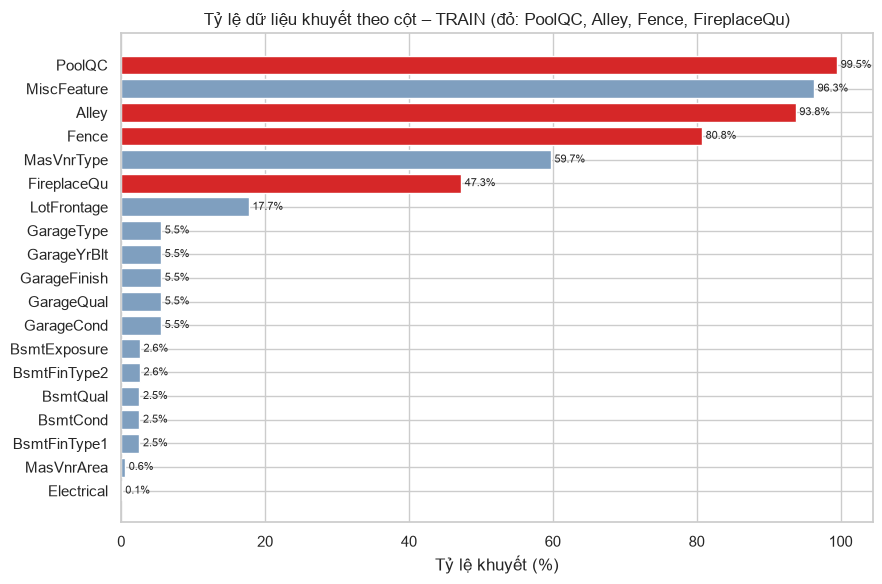

In [4]:
# Trọng tâm: 4 cột khuyết nhiều nhất theo yêu cầu
KEY = ['PoolQC', 'Alley', 'Fence', 'FireplaceQu']
display(report_train.loc[KEY])

fig, ax = plt.subplots(figsize=(9, 6))
plot_df = report_train.reset_index().rename(columns={'index': 'Cột'})
colors = ['#d62728' if c in KEY else '#7f9fbf' for c in plot_df['Cột']]
ax.barh(plot_df['Cột'], plot_df['Tỷ lệ khuyết (%)'], color=colors)
ax.invert_yaxis()
ax.set_xlabel('Tỷ lệ khuyết (%)')
ax.set_title('Tỷ lệ dữ liệu khuyết theo cột – TRAIN (đỏ: PoolQC, Alley, Fence, FireplaceQu)')
for i, v in enumerate(plot_df['Tỷ lệ khuyết (%)']):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=8)
plt.tight_layout(); plt.show()

In [5]:
report_test = missing_report(test_raw, 'TEST')
display(report_test)

[TEST] 33/80 cột có khuyết | 7878 ô khuyết (6.75% tổng số ô)


,Số dòng khuyết,Tỷ lệ khuyết (%),Nhóm biến,Kiểu dữ liệu,Nguyên nhân khuyết
PoolQC,1456,99.79,Phân loại – thứ tự,str,Không có hồ bơi
MiscFeature,1408,96.50,Phân loại – danh nghĩa,str,Không có tiện ích khác
Alley,1352,92.67,Phân loại – danh nghĩa,str,Không có đường hẻm
Fence,1169,80.12,Phân loại – thứ tự,str,Không có hàng rào
MasVnrType,894,61.27,Phân loại – danh nghĩa,str,Không ốp gạch/đá
FireplaceQu,730,50.03,Phân loại – thứ tự,str,Không có lò sưởi
LotFrontage,227,15.56,Số – liên tục,float64,Khuyết thực sự → nội suy theo Neighborhood
GarageQual,78,5.35,Phân loại – thứ tự,str,Không có gara
GarageCond,78,5.35,Phân loại – thứ tự,str,Không có gara
GarageYrBlt,78,5.35,Số – rời rạc,float64,Không có gara


## 3. Điền khuyết theo logic nghiệp vụ

**Nguyên tắc:** một ô khuyết cần được hỏi *"ngôi nhà này có đặc trưng đó không?"*

| Tình huống | Cách điền |
|---|---|
| Nhà **không có** cấu trúc (hồ bơi, hầm, gara, lò sưởi, ốp gạch) | Cột phân loại → `"None"`, cột số → `0` |
| Nhà **có** cấu trúc nhưng thiếu thuộc tính (khuyết thực sự) | Cột phân loại → mode, cột số → median, tính trên các nhà *có* cấu trúc đó (từ train) |
| `Alley`, `Fence` (không có cột nào chứng minh sự tồn tại) | `"None"` |
| Khuyết ngẫu nhiên (`Electrical`, `MSZoning`, ...) | mode (phân loại) / median (số), tính từ train |

Việc xác định "có cấu trúc hay không" dựa vào cột đo lường liên quan (`PoolArea`, `TotalBsmtSF`, `GarageArea`/`GarageType`, `Fireplaces`, `MasVnrArea`, `MiscVal`).

In [6]:
# Mỗi cấu trúc: (cột phân loại, cột số, hàm xác định "nhà CÓ cấu trúc")
STRUCTURES = {
    'Hồ bơi': (['PoolQC'], ['PoolArea'],
               lambda d: d['PoolArea'].fillna(0) > 0),
    'Tầng hầm': (['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2'],
                 ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath'],
                 lambda d: d['TotalBsmtSF'].fillna(0) > 0),
    'Gara': (['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond'],
             ['GarageCars', 'GarageArea', 'GarageYrBlt'],
             lambda d: d['GarageType'].notna() | (d['GarageArea'].fillna(0) > 0)),
    'Lò sưởi': (['FireplaceQu'], [],
                lambda d: d['Fireplaces'].fillna(0) > 0),
    'Ốp gạch/đá': ([], ['MasVnrArea'],
                   lambda d: d['MasVnrArea'].fillna(0) > 0),
    'Tiện ích khác': (['MiscFeature'], [],
                      lambda d: d['MiscVal'].fillna(0) > 0),
}
# Alley, Fence: không có cột nào xác nhận sự tồn tại.
# MasVnrType: chuỗi "None" hợp lệ (không ốp) bị pandas đọc thành NaN, không phân biệt được với khuyết thật
# (cả những nhà có MasVnrArea > 0 nhưng loại = "None") → luôn điền "None".
ALWAYS_NONE = ['Alley', 'Fence', 'MasVnrType']

def fit_fill_values(ref):
    """Học mode/median từ TRAIN, chỉ trên các nhà có cấu trúc tương ứng."""
    vals = {}
    for name, (cat, num, has) in STRUCTURES.items():
        mask = has(ref)
        for c in cat:
            s = ref.loc[mask, c].dropna()
            vals[c] = s.mode()[0] if len(s) else 'None'
        for c in num:
            s = ref.loc[mask, c].dropna()
            vals[c] = s.median() if len(s) else 0
    return vals

fill_values = fit_fill_values(train_raw)

def impute_structural(df):
    df = df.copy()
    log = []
    # Tính mask TRƯỚC khi điền để không bị ảnh hưởng thứ tự
    masks = {name: has(df) for name, (_, _, has) in STRUCTURES.items()}
    for name, (cat, num, _) in STRUCTURES.items():
        present = masks[name]
        for c in cat:
            na = df[c].isna()
            n_abs, n_pre = int((na & ~present).sum()), int((na & present).sum())
            df.loc[na & ~present, c] = 'None'
            df.loc[na & present, c] = fill_values[c]
            if n_abs + n_pre: log.append((name, c, 'None', n_abs, fill_values[c], n_pre))
        for c in num:
            na = df[c].isna()
            n_abs, n_pre = int((na & ~present).sum()), int((na & present).sum())
            df.loc[na & ~present, c] = 0
            if c == 'GarageYrBlt':   # có gara nhưng thiếu năm xây → dùng năm xây nhà
                df.loc[na & present, c] = df.loc[na & present, 'YearBuilt']
                fv = 'YearBuilt'
            else:
                df.loc[na & present, c] = fill_values[c]; fv = fill_values[c]
            if n_abs + n_pre: log.append((name, c, 0, n_abs, fv, n_pre))
    for c in ALWAYS_NONE:
        n = int(df[c].isna().sum()); df[c] = df[c].fillna('None')
        if n: log.append(('Không có cấu trúc', c, 'None', n, '-', 0))
    return df, pd.DataFrame(log, columns=['Cấu trúc', 'Cột', 'Giá trị khi "không có"', 'Số ô',
                                          'Giá trị khi "có nhưng thiếu"', 'Số ô '])

train, log_train = impute_structural(train)
test,  log_test  = impute_structural(test)

print('TRAIN – nhật ký điền khuyết theo cấu trúc'); display(log_train)
print('TEST  – nhật ký điền khuyết theo cấu trúc'); display(log_test)

TRAIN – nhật ký điền khuyết theo cấu trúc


,Cấu trúc,Cột,"Giá trị khi ""không có""",Số ô,"Giá trị khi ""có nhưng thiếu""",Số ô
0,Hồ bơi,PoolQC,None,1453,Gd,0
1,Tầng hầm,BsmtQual,None,37,TA,0
2,Tầng hầm,BsmtCond,None,37,TA,0
3,Tầng hầm,BsmtExposure,None,37,No,1
4,Tầng hầm,BsmtFinType1,None,37,Unf,0
5,Tầng hầm,BsmtFinType2,None,37,Unf,1
6,Gara,GarageType,None,81,Attchd,0
7,Gara,GarageFinish,None,81,Unf,0
8,Gara,GarageQual,None,81,TA,0
9,Gara,GarageCond,None,81,TA,0


TEST  – nhật ký điền khuyết theo cấu trúc


,Cấu trúc,Cột,"Giá trị khi ""không có""",Số ô,"Giá trị khi ""có nhưng thiếu""",Số ô
0,Hồ bơi,PoolQC,None,1453,Gd,3
1,Tầng hầm,BsmtQual,None,42,TA,2
2,Tầng hầm,BsmtCond,None,42,TA,3
3,Tầng hầm,BsmtExposure,None,42,No,2
4,Tầng hầm,BsmtFinType1,None,42,Unf,0
5,Tầng hầm,BsmtFinType2,None,42,Unf,0
6,Tầng hầm,BsmtFinSF1,0,1,400.0,0
7,Tầng hầm,BsmtFinSF2,0,1,0.0,0
8,Tầng hầm,BsmtUnfSF,0,1,490.0,0
9,Tầng hầm,TotalBsmtSF,0,1,1004.0,0


### Khuyết ngẫu nhiên còn lại (mode / median từ train)

In [7]:
RANDOM_CAT = ['Electrical', 'MSZoning', 'Utilities', 'Functional', 'Exterior1st',
              'Exterior2nd', 'KitchenQual', 'SaleType']

for c in RANDOM_CAT:
    mode_val = train_raw[c].mode()[0]
    for d in (train, test):
        d[c] = d[c].fillna(mode_val)

# Lưới an toàn: cột nào ngoài LotFrontage còn khuyết thì điền theo kiểu dữ liệu và báo cáo lại
for d, nm in ((train, 'train'), (test, 'test')):
    for c in d.columns:
        if c in ('LotFrontage', TARGET) or not d[c].isna().any():
            continue
        fill = train_raw[c].median() if pd.api.types.is_numeric_dtype(d[c]) else train_raw[c].mode()[0]
        print(f'[safety-net] {nm}.{c}: {d[c].isna().sum()} ô → {fill}')
        d[c] = d[c].fillna(fill)

print('Còn khuyết sau bước này:')
print('  train:', train.drop(columns='LotFrontage').isna().sum().sum(),
      '| test:', test.drop(columns='LotFrontage').isna().sum().sum())

Còn khuyết sau bước này:
  train: 0 | test: 0


## 4. Nội suy `LotFrontage` bằng trung vị theo `Neighborhood`

`LotFrontage` (chiều dài mặt tiền tiếp giáp đường) phụ thuộc mạnh vào khu vực nên dùng **trung vị theo khu phố** thay vì trung bình toàn cục. Trung vị được tính **chỉ từ train** rồi áp cho cả train và test.

In [8]:
lf_median_by_nb = train_raw.groupby('Neighborhood')['LotFrontage'].median()
lf_global_median = train_raw['LotFrontage'].median()
display(lf_median_by_nb.round(1).to_frame('Median LotFrontage').T)

def impute_lotfrontage(df):
    df = df.copy()
    before = int(df['LotFrontage'].isna().sum())
    df['LotFrontage'] = df['LotFrontage'].fillna(df['Neighborhood'].map(lf_median_by_nb))
    fallback = int(df['LotFrontage'].isna().sum())          # khu phố không có dữ liệu nào
    df['LotFrontage'] = df['LotFrontage'].fillna(lf_global_median)
    print(f'  khuyết ban đầu: {before} | điền theo Neighborhood: {before - fallback} | '
          f'dự phòng bằng median toàn cục: {fallback}')
    return df

print('TRAIN'); train = impute_lotfrontage(train)
print('TEST');  test  = impute_lotfrontage(test)

print(f"\nLotFrontage train – trước: mean={train_raw['LotFrontage'].mean():.2f}, "
      f"median={train_raw['LotFrontage'].median():.2f} | sau: mean={train['LotFrontage'].mean():.2f}, "
      f"median={train['LotFrontage'].median():.2f}")

Neighborhood,Blmngtn,Blueste,BrDale,BrkSide,ClearCr,CollgCr,Crawfor,Edwards,Gilbert,IDOTRR,MeadowV,Mitchel,NAmes,NPkVill,NWAmes,NoRidge,NridgHt,OldTown,SWISU,Sawyer,SawyerW,Somerst,StoneBr,Timber,Veenker
Median LotFrontage,43.0,24.0,21.0,52.0,80.0,70.0,74.0,65.5,65.0,60.0,21.0,73.0,73.0,24.0,80.0,91.0,88.5,60.0,60.0,71.0,66.5,73.5,61.5,85.0,68.0


TRAIN
  khuyết ban đầu: 259 | điền theo Neighborhood: 259 | dự phòng bằng median toàn cục: 0
TEST
  khuyết ban đầu: 227 | điền theo Neighborhood: 227 | dự phòng bằng median toàn cục: 0

LotFrontage train – trước: mean=70.05, median=69.00 | sau: mean=70.20, median=70.00


## 5. Kiểm tra đầu ra – 100% không còn NaN

In [9]:
na_train, na_test = int(train.isna().sum().sum()), int(test.isna().sum().sum())
print(f'NaN train: {na_train} | NaN test: {na_test}')
print(f'Shape train: {train.shape} | test: {test.shape}')
assert na_train == 0 and na_test == 0, 'Vẫn còn NaN!'
assert train.shape == train_raw.shape and test.shape == test_raw.shape, 'Số dòng/cột bị thay đổi'
assert (train['Id'].values == train_raw['Id'].values).all()
print('✅ Dữ liệu đã được lấp đầy 100%')

# Báo cáo trước/sau cho các cột trọng tâm
cmp = pd.DataFrame({
    'Khuyết trước (%)': (train_raw[KEY + ['LotFrontage']].isna().mean() * 100).round(2),
    'Khuyết sau (%)': (train[KEY + ['LotFrontage']].isna().mean() * 100).round(2),
})
display(cmp)
print(train[KEY].apply(lambda s: s.value_counts().head(3).to_dict()))

NaN train: 0 | NaN test: 0
Shape train: (1460, 81) | test: (1459, 80)
✅ Dữ liệu đã được lấp đầy 100%


,Khuyết trước (%),Khuyết sau (%)
PoolQC,99.52,0.0
Alley,93.77,0.0
Fence,80.75,0.0
FireplaceQu,47.26,0.0
LotFrontage,17.74,0.0


PoolQC                  {'None': 1453, 'Gd': 3, 'Ex': 2}
Alley             {'None': 1369, 'Grvl': 50, 'Pave': 41}
Fence          {'None': 1179, 'MnPrv': 157, 'GdPrv': 59}
FireplaceQu          {'None': 690, 'Gd': 380, 'TA': 313}
dtype: object


In [10]:
# Lưu ý: khi nạp lại file đã lưu phải dùng keep_default_na=False,
# nếu không pandas sẽ đọc chuỗi "None" thành NaN trở lại.
train.to_csv('../Data/train_filled.csv', index=False)
test.to_csv('../Data/test_filled.csv', index=False)

chk_tr = pd.read_csv('../Data/train_filled.csv', keep_default_na=False, na_values=[''])
chk_te = pd.read_csv('../Data/test_filled.csv',  keep_default_na=False, na_values=[''])
print('Nạp lại → NaN train:', chk_tr.isna().sum().sum(), '| NaN test:', chk_te.isna().sum().sum())

Nạp lại → NaN train: 0 | NaN test: 0


---
## 6. Mở rộng: Feature Engineering (giữ lại từ notebook gốc, đã sửa lỗi)

Các bước này chạy trên dữ liệu **đã lấp đầy** nên không cần các ô điền khuyết rải rác như bản cũ. Các lỗi đã sửa:
- `TotalPorchSF` của **test** dùng `np.expm1` trong khi dữ liệu chưa hề log → sai giá trị; nay dùng cùng công thức với train.
- Bỏ các ô tính lặp `TotalBath` / `TotalSF` (vì giờ không còn NaN phải tính lại).

In [11]:
train_fe, test_fe = train.copy(), test.copy()

def add_features(d):
    d['TotalSF']      = d['TotalBsmtSF'] + d['1stFlrSF'] + d['2ndFlrSF']
    d['HouseAge']     = d['YrSold'] - d['YearBuilt']
    d['RemodAge']     = d['YrSold'] - d['YearRemodAdd']
    d['TotalBath']    = d['FullBath'] + 0.5 * d['HalfBath'] + d['BsmtFullBath'] + 0.5 * d['BsmtHalfBath']
    d['HasGarage']    = (d['GarageArea'] > 0).astype(int)
    d['HasBsmt']      = (d['TotalBsmtSF'] > 0).astype(int)
    d['HasFireplace'] = (d['Fireplaces'] > 0).astype(int)
    d['Has2ndFloor']  = (d['2ndFlrSF'] > 0).astype(int)
    d['TotalPorchSF'] = (d['OpenPorchSF'] + d['3SsnPorch'] + d['EnclosedPorch']
                         + d['ScreenPorch'] + d['WoodDeckSF'])
    return d

train_fe, test_fe = add_features(train_fe), add_features(test_fe)
display(train_fe[['TotalSF', 'HouseAge', 'RemodAge', 'TotalBath', 'HasGarage', 'HasBsmt',
                  'HasFireplace', 'Has2ndFloor', 'TotalPorchSF']].head())

,TotalSF,HouseAge,RemodAge,TotalBath,HasGarage,HasBsmt,HasFireplace,Has2ndFloor,TotalPorchSF
0,2566,5,5,3.5,1,1,0,1,61
1,2524,31,31,2.5,1,1,1,0,298
2,2706,7,6,3.5,1,1,1,1,42
3,2473,91,36,2.0,1,1,1,1,307
4,3343,8,8,3.5,1,1,1,1,276


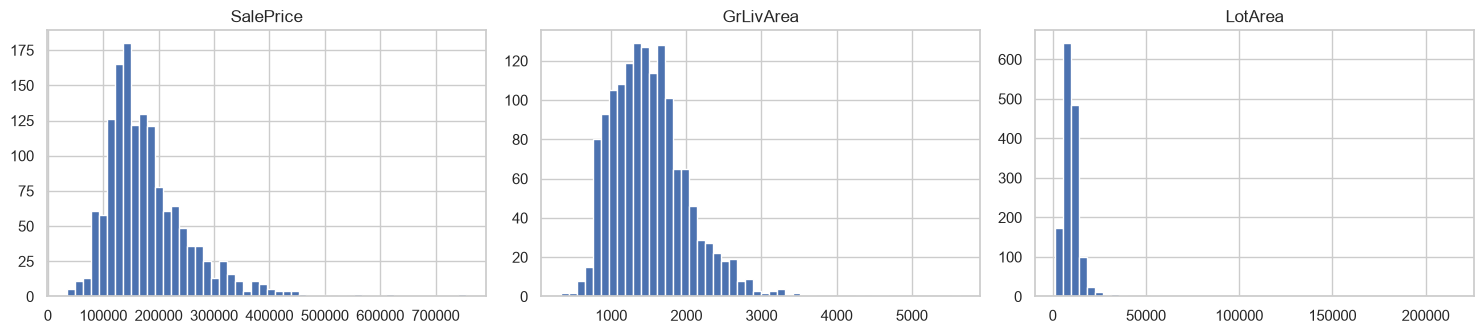

,Tương quan với SalePrice
SalePrice,1.000000
OverallQual,0.790982
TotalSF,0.782260
GrLivArea,0.708624
GarageCars,0.640409
TotalBath,0.631731
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ['SalePrice', 'GrLivArea', 'LotArea']):
    train_fe[col].hist(bins=50, ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

corr = train_fe.select_dtypes(include=np.number).corr()
display(corr['SalePrice'].sort_values(ascending=False).head(15).to_frame('Tương quan với SalePrice'))

In [13]:
log_features = ['MiscVal', 'PoolArea', 'LotArea', '3SsnPorch', 'LowQualFinSF', 'BsmtFinSF2',
                'ScreenPorch', 'EnclosedPorch', 'MasVnrArea', 'LotFrontage', 'OpenPorchSF',
                'BsmtFinSF1', 'WoodDeckSF', 'TotalBsmtSF', '1stFlrSF', 'GrLivArea', 'TotalSF']

print('Độ lệch (skew) trước log:'); print(train_fe[log_features].skew().sort_values(ascending=False).round(2).head(8))
for col in log_features:
    train_fe[col] = np.log1p(train_fe[col])
    test_fe[col]  = np.log1p(test_fe[col])
print('\nĐộ lệch (skew) sau log:'); print(train_fe[log_features].skew().sort_values(ascending=False).round(2).head(8))

Độ lệch (skew) trước log:
MiscVal          24.48
PoolArea         14.83
LotArea          12.21
3SsnPorch        10.30
LowQualFinSF      9.01
BsmtFinSF2        4.26
ScreenPorch       4.12
EnclosedPorch     3.09
dtype: float64

Độ lệch (skew) sau log:
PoolArea         14.36
3SsnPorch         7.73
LowQualFinSF      7.46
MiscVal           5.17
ScreenPorch       3.15
BsmtFinSF2        2.52
EnclosedPorch     2.11
MasVnrArea        0.50
dtype: float64


In [14]:
print('Cột chỉ có ở train:', set(train_fe.columns) - set(test_fe.columns))
print('Cột chỉ có ở test :', set(test_fe.columns) - set(train_fe.columns))
print('Train shape:', train_fe.shape, '| Test shape:', test_fe.shape)
print('NaN train_fe:', train_fe.isna().sum().sum(), '| NaN test_fe:', test_fe.isna().sum().sum())
assert train_fe.isna().sum().sum() == 0 and test_fe.isna().sum().sum() == 0

train_fe.to_csv('../Data/train_fe.csv', index=False)
test_fe.to_csv('../Data/test_fe.csv', index=False)

Cột chỉ có ở train: {'SalePrice'}
Cột chỉ có ở test : set()
Train shape: (1460, 90) | Test shape: (1459, 89)
NaN train_fe: 0 | NaN test_fe: 0
